# 04 — Exploratory Analysis of the Preprocessed Business Records

## 1. Purpose of This Notebook

This notebook describes the business dataset prepared in Notebook 02 and shows what preprocessing changed. It uses
**only the Ministry of Commerce business records** and reads only the output of Notebook 02 (`02_businesses.parquet`);
the economic indicators of GASTAT and SAMA are studied in Sprint 3. Nothing in the dataset is changed; only the figures
are saved, in `ml/report_figures`, so the notebook can be run again at any time.

The notebook proceeds in seven stages:

1. The problems found before preprocessing (Notebook 01) and how preprocessing resolved them.
2. The labelled businesses and the time split.
3. Reliability of the survival target.
4. Distribution of the business characteristics.
5. Failure rate by business characteristic.
6. Missing values by outcome.
7. Failure rate by founding month.

**Test data never opened.** The outcome of a business is examined only for the businesses founded from 2023 Q1 to
2024 Q4 (the training businesses). The businesses founded from 2025 Q1 to 2025 Q3 are counted and then set aside,
and their outcome is not examined.

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.simplefilter('ignore', FutureWarning)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (11, 4)
FIGURES = Path.cwd().parent / 'report_figures'   # figures used in the report (PNG, 300 dpi)
FIGURES.mkdir(exist_ok=True)

businesses = pd.read_parquet(need(PIPE / '02_businesses.parquet', '02_preprocess_businesses'))
print(f'Businesses loaded from Notebook 02: {len(businesses):,}')
INCOMPLETE = ['2023Q3', '2024Q3', '2024Q4', '2025Q1', '2025Q3']   # incomplete quarterly files (Notebook 01, section A11)
present = businesses.filter(like='present_').rename(columns=lambda c: c.removeprefix('present_'))

# English names, used in the charts because Arabic text is not shaped by the plotting library
SECTION_NAMES = {'A': 'Agriculture, forestry and fishing', 'B': 'Mining and quarrying', 'C': 'Manufacturing',
                 'D': 'Electricity and gas supply', 'E': 'Water supply and waste management', 'F': 'Construction',
                 'G': 'Wholesale and retail trade', 'H': 'Transportation and storage', 'I': 'Accommodation and food service',
                 'J': 'Information and communication', 'K': 'Financial and insurance', 'L': 'Real estate',
                 'M': 'Professional, scientific and technical', 'N': 'Administrative and support services',
                 'O': 'Public administration', 'P': 'Education', 'Q': 'Human health and social work',
                 'R': 'Arts, entertainment and recreation', 'S': 'Other service activities', 'T': 'Households as employers',
                 'U': 'Extraterritorial organizations', 'unclassified': 'unclassified'}
LEGAL_FORM_NAMES = {'مؤسسة فردية': 'Sole proprietorship', 'الشركة ذات المسؤولية المحدودة': 'Limited liability company',
                    'شركة التضامن': 'General partnership', 'فرع شركة أجنبية': 'Branch of a foreign company',
                    'شركة المساهمة': 'Joint stock company', 'شركة التوصية البسيطة': 'Limited partnership',
                    'شركة المساهمة المبسطة': 'Simplified joint stock company', 'غير محدد': 'Not specified'}
REGION_NAMES = {'الرياض': 'Riyadh', 'مكة المكرمة': 'Makkah', 'الشرقية': 'Eastern Province', 'القصيم': 'Qassim',
                'عسير': 'Asir', 'المدينة المنورة': 'Madinah', 'جازان': 'Jazan', 'نجران': 'Najran', 'حائل': 'Hail',
                'تبوك': 'Tabuk', 'الجوف': 'Al Jouf', 'الحدود الشمالية': 'Northern Borders', 'الباحة': 'Al Baha'}

Businesses loaded from Notebook 02: 2,100,756


## 3. Stage 1 — Problems Found Before Preprocessing and Their Resolution

Each problem found in the raw records (Notebook 01, section 3) is checked again in the business dataset produced by
Notebook 02. The cell measures, on that dataset, the value that shows whether the problem is resolved.

businesses                                           2100756.00
businesses without a registration number                   0.00
registration numbers appearing twice                       0.00
distinct regions                                          13.00
distinct legal forms                                       8.00
businesses whose legal form cannot be assigned            34.00
distinct cities                                          244.00
businesses with an unmapped locality                    1337.00
businesses without a valid founding date                   0.00
businesses without a real capital                          0.00
capital of −1, 0 or 1 SAR                                  0.00
smallest capital (SAR)                                     0.01
former branches without a label                        31856.00
e-commerce not recorded, first seen up to 2025 Q2          0.00
e-commerce not recorded, first seen from 2025 Q4           1.00

        businesses present (after compl

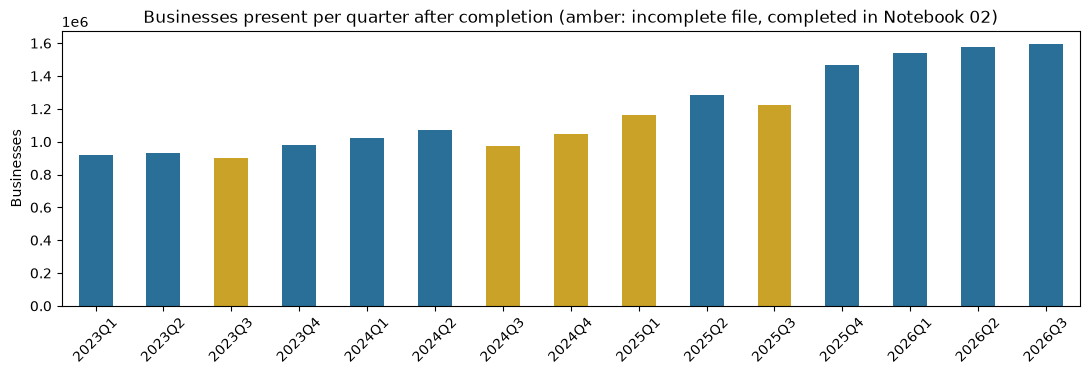

In [3]:
after = {
    'businesses': len(businesses),
    'businesses without a registration number': int(businesses.index.isna().sum()),
    'registration numbers appearing twice': int(businesses.index.duplicated().sum()),
    'distinct regions': businesses['region'].nunique(),
    'distinct legal forms': businesses['legal_form'].nunique(),
    'businesses whose legal form cannot be assigned': int((businesses['legal_form'] == 'غير محدد').sum()),
    'distinct cities': businesses.loc[businesses['city'] != 'unmapped', 'city'].nunique(),
    'businesses with an unmapped locality': int((businesses['city'] == 'unmapped').sum()),
    'businesses without a valid founding date': int(businesses['founding_date'].isna().sum()),
    'businesses without a real capital': int(businesses['registered_capital_sar'].isna().sum()),
    'capital of −1, 0 or 1 SAR': int(businesses['registered_capital_sar'].isin([-1, 0, 1]).sum()),
    'smallest capital (SAR)': businesses['registered_capital_sar'].min(),
    'former branches without a label': int((businesses['label_reason'] == 'former_branch_registration').sum()),
    'e-commerce not recorded, first seen up to 2025 Q2': businesses.loc[businesses['first_seen_quarter'] <= '2025Q2', 'ecommerce_disclosed'].isna().mean(),
    'e-commerce not recorded, first seen from 2025 Q4': businesses.loc[businesses['first_seen_quarter'] >= '2025Q4', 'ecommerce_disclosed'].isna().mean(),
}
print(pd.Series(after).to_string())

quarters = present.sum().rename('businesses present (after completion)').to_frame()
quarters['quarterly file'] = np.where(quarters.index.isin(INCOMPLETE), 'incomplete, completed', 'complete')
print('\n', quarters.to_string(formatters={'businesses present (after completion)': '{:,}'.format}))
ax = quarters['businesses present (after completion)'].plot.bar(
    color=np.where(quarters.index.isin(INCOMPLETE), '#c9a227', '#2a6f97'), rot=45,
    title='Businesses present per quarter after completion (amber: incomplete file, completed in Notebook 02)')
ax.set_ylabel('Businesses'); plt.tight_layout(); plt.show()

**Result.** Every problem found before preprocessing was checked again on the 2,100,756 businesses of the dataset:

| Problem found before preprocessing (Notebook 01) | Before | Resolution (Notebook 02) | After |
|---|---|---|---|
| Part 1 of 2025 Q3 has no registration number (finding 3) | 109,541 records | Number recovered by business name, founding date and city from 2025 Q2 or 2025 Q4; 839 records that could not be recovered excluded | Every business has a registration number |
| A registration number appears twice in a quarter (A3) | 2 numbers | The second occurrence is not counted | Each registration number appears once |
| A header row repeated inside the 2026 Q2 file (finding 5) | 1 row, 14 regions | Row removed | 13 regions |
| Branch registrations recorded beside the main registrations (finding 13) | 4,381,234 rows | Branch rows removed; a business is its main registration. 4,402,728 rows were removed: 44,856 recovered 2025 Q3 rows took the branch type of 2025 Q2, and 23,362 rows were corrected to main registrations | No branch registration |
| Branches that became main registrations after the law of 2025 (finding 14) | 15,512 in 2025 Q4, 19,844 more by 2026 Q3 | Every registration recorded as a branch before its first record as a main registration is a former branch (61,585); it is kept as a business, but given no survival label | 61,144 former branches in the dataset (441 excluded with no founding date or real capital); 29,288 were founded before 2023 and have no label in any case, and the other 31,856 have no label because they are former branches |
| Main registrations recorded as branches after the law (finding 14) | 2,215 in 2025 Q4 | Corrected to main registrations | Present as main registrations |
| Five incomplete quarterly files (finding 15) | 35.8% to 85.4% of active businesses found | A business present before and after an incomplete quarter is counted as present in it | 899,504 to 1,221,709 businesses present in those quarters, close to their complete neighbours |
| Legal form written in 40 to 53 ways (finding 11) | 102 recorded values | Mapped to the forms of the Companies Law | 8 legal forms; 34 businesses whose form cannot be assigned are kept |
| City recorded as a locality from 2025 Q2 (finding 10) | 1,724 to 4,726 values per quarter | Each locality assigned to its city of 2025 Q1 | 244 cities; 1,337 businesses with an unmapped locality are kept with their region |
| Founding dates that cannot be interpreted or precede 1950 (finding 7) | 836 and 9 records | Businesses without any valid date excluded | No business without a founding date |
| Capital empty, or written as −1, 0 or 1 SAR (findings 8, 9) | 504,202 empty, 3,139 negative, 10,773 zero records | Capital of the first record, or of the next record when founded in the quarter of the first record; otherwise excluded | No business without a real capital; no capital of −1, 0 or 1 SAR |
| E-commerce disclosure not reported from 2025 Q4 (finding 12) | 100% not reported from 2025 Q4 | Not imputed | Recorded for every business first seen up to 2025 Q2; missing for every business first seen from 2025 Q4 |

After completion, each of the fifteen quarters contains between 899,504 and 1,594,003 businesses, and the five
completed quarters no longer stand out from their neighbours.

**Interpretation.** Every problem identified in the raw records is either resolved or, where the records cannot resolve it, stated
together with the businesses it concerns. The only attribute that remains missing because of the period of the file
is the e-commerce disclosure. The smallest capital of the dataset is 0.01 SAR; only the values −1, 0 and 1 SAR were
treated as unknown, so other very small amounts remain as recorded.

## 4. Stage 2 — The Labelled Businesses and the Time Split

The labelled businesses are split by founding quarter, so that the outcome of the most recent businesses is not
examined before the model is built:

| Set | Founding quarters | Use |
|---|---|---|
| Training | 2023 Q1 to 2024 Q4 | Studied in this notebook |
| Validation | 2025 Q1 and 2025 Q2 | Comparison of models |
| Test | 2025 Q3 | Final evaluation, opened once |

            businesses  share
training        552136  64.9%
validation      177893  20.9%
test            120222  14.1%


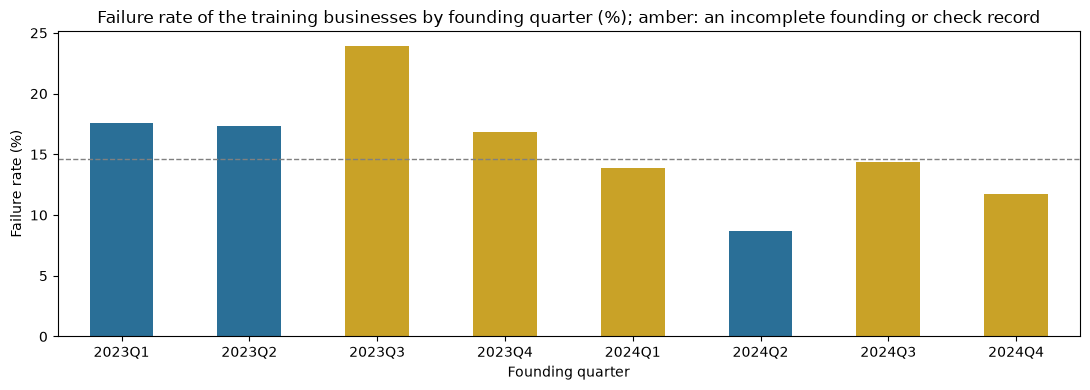

Training businesses: 552,136 | failed 80,541 (14.6%) | survived 471,595
                 businesses failed failure_rate  check_record_complete  founding_record_complete
founding_quarter                                                                                
2023Q1               47,926  8,436        17.6%                   True                      True
2023Q2               42,109  7,291        17.3%                   True                      True
2023Q3               51,636 12,357        23.9%                  False                     False
2023Q4               64,253 10,806        16.8%                  False                      True
2024Q1               71,207  9,877        13.9%                  False                      True
2024Q2               92,278  7,998         8.7%                   True                      True
2024Q3               87,684 12,609        14.4%                  False                     False
2024Q4               95,043 11,167        11.7%        

In [4]:
SPLIT = {'training': ('2023Q1', '2024Q4'), 'validation': ('2025Q1', '2025Q2'), 'test': ('2025Q3', '2025Q3')}
labelled = businesses[businesses['survived_first_year'].notna()]
split = pd.Series(pd.NA, index=labelled.index, dtype='string')
for name, (first, last) in SPLIT.items():
    split[labelled['founding_quarter'].between(first, last)] = name
assert split.notna().all(), 'A labelled business falls outside the split'
print(pd.DataFrame({'businesses': split.value_counts().reindex(SPLIT.keys()),
                    'share': split.value_counts(normalize=True).reindex(SPLIT.keys()).map('{:.1%}'.format)}).to_string())

training = labelled[split == 'training'].copy()
training['failed'] = 1 - training['survived_first_year'].astype(int)
del labelled, split

per_quarter = training.groupby('founding_quarter').agg(
    businesses=('failed', 'size'), failed=('failed', 'sum'), failure_rate=('failed', 'mean'),
    check_record_complete=('check_record_complete', 'first'))
per_quarter['founding_record_complete'] = ~per_quarter.index.isin(INCOMPLETE)
colors = np.where(per_quarter['founding_record_complete'] & per_quarter['check_record_complete'], '#2a6f97', '#c9a227')
ax = (per_quarter['failure_rate'] * 100).plot.bar(color=colors, rot=0)
ax.axhline(training['failed'].mean() * 100, color='grey', ls='--', lw=1)
ax.set_title('Failure rate of the training businesses by founding quarter (%); amber: an incomplete founding or check record')
ax.set_xlabel('Founding quarter'); ax.set_ylabel('Failure rate (%)')
plt.tight_layout(); plt.savefig(FIGURES / '04_stage2_failure_by_founding_quarter.png', dpi=300); plt.show()
print(f'Training businesses: {len(training):,} | failed {int(training["failed"].sum()):,} ({training["failed"].mean():.1%}) | '
      f'survived {int((training["failed"] == 0).sum()):,}')
print(per_quarter.to_string(formatters={'businesses': '{:,}'.format, 'failed': '{:,}'.format, 'failure_rate': '{:.1%}'.format}))

**Result.** Of the 850,251 labelled businesses, 552,136 (64.9%) form the training set, 177,893 (20.9%) the validation set and
120,222 (14.1%) the test set. Of the training businesses, 80,541 failed (14.6%) and 471,595 survived. The failure
rate ranges from 8.7% (2024 Q2) to 23.9% (2023 Q3); only 2023 Q1, 2023 Q2 and 2024 Q2 have both a complete founding
record and a complete survival check record.

**Interpretation.** Failure is the minority outcome, about one business in seven. The failure rate differs between founding quarters
partly because of the completeness of the records.

## 5. Stage 3 — Reliability of the Survival Target

Some groups of businesses have a label that may be less reliable. This
cell gives the size and failure rate of each group among the training businesses:

| Group | Definition | Source |
|---|---|---|
| Failed, reappeared later | Absent at the survival check, present in a later record | Notebook 02, section 6.1 |
| First seen after the check | First recorded after the survival check quarter; labelled failed, as it was absent at the check | Notebook 02, section 6 |
| Founding record incomplete | Founded in an incomplete quarterly record | Notebook 02, section 6, limitation 8 |
| Check record incomplete | Checked in an incomplete quarterly record | Notebook 02, section 6 |

The former branches (Notebook 02, section 4.2) have no label, so they are counted separately.

In [5]:
groups = {'failed, reappeared later': training['label_reason'] == 'absent_at_check_reappeared_later',
          'first seen after the check': training['first_seen_quarter'] > training['survival_check_quarter'],
          'founding record incomplete': training['founding_quarter'].isin(INCOMPLETE),
          'check record incomplete': ~training['check_record_complete']}
reliability = pd.DataFrame({'businesses': {g: int(m.sum()) for g, m in groups.items()},
                            'share of training': {g: m.mean() for g, m in groups.items()},
                            'failure rate': {g: training.loc[m, 'failed'].mean() for g, m in groups.items()}})
print(reliability.to_string(formatters={'businesses': '{:,}'.format, 'share of training': '{:.1%}'.format, 'failure rate': '{:.1%}'.format}))
print(f'\nFailure rate of all training businesses: {training["failed"].mean():.1%}')
in_training_period = businesses['founding_quarter'].between('2023Q1', '2024Q4')
former = businesses[in_training_period & (businesses['label_reason'] == 'former_branch_registration')]
print(f'Former branches founded from 2023 Q1 to 2024 Q4 (no label): {len(former):,}')

                           businesses share of training failure rate
failed, reappeared later        7,602              1.4%       100.0%
first seen after the check      2,110              0.4%       100.0%
founding record incomplete    234,363             42.4%        15.4%
check record incomplete       274,780             49.8%        16.6%

Failure rate of all training businesses: 14.6%
Former branches founded from 2023 Q1 to 2024 Q4 (no label): 28,095


**Result.** 7,602 training businesses (1.4%) failed and reappeared in a later record, and 2,110 (0.4%) are first recorded after their
survival check quarter; both groups are labelled failed. 42.4% of the training businesses were founded in a quarter with
an incomplete record (failure rate 15.4%), and 49.8% were checked in one (16.6%), against 14.6% for all training
businesses. 28,095 former branches founded from 2023 Q1 to 2024 Q4 have no label.

**Interpretation.** Before the former branches were identified, 20,769 training businesses were first recorded after their survival
check and 26,362 reappeared later; most of them were branches that became main registrations after the law of 2025,
not businesses that closed. The remaining 2,110 businesses first recorded after their check are labelled failed,
because they were not active at the check. Businesses checked in an incomplete record fail slightly more often than
the others (16.6% against 14.6%), which is consistent with the risk that a business active at its check but missing
from an incomplete file is recorded as failed.

## 6. Stage 4 — Distribution of the Business Characteristics

The characteristics are those entered by a founder in Darb: legal form, region, sector, registered capital and
e-commerce. Registered capital is strongly skewed, so its distribution is shown on a logarithmic scale.


legal_form (share of training businesses)


legal_form
Sole proprietorship               70.4%
Limited liability company         29.2%
Branch of a foreign company        0.2%
Simplified joint stock company     0.1%
General partnership                0.1%
Joint stock company                0.0%
Limited partnership                0.0%
Not specified                      0.0%

region (share of training businesses)
region
Riyadh              38.4%
Makkah              19.0%
Eastern Province    15.5%
Madinah              4.8%
Qassim               4.7%
Asir                 4.7%
Jazan                3.1%
Najran               2.5%
Hail                 2.5%
Tabuk                2.2%
Al Jouf              1.0%
Northern Borders     0.9%
Al Baha              0.6%



sector (share of training businesses)
sector
Construction                              28.5%
unclassified                              27.5%
Wholesale and retail trade                12.3%
Accommodation and food service             7.8%
Transportation and storage                 4.9%
Other service activities                   3.9%
Manufacturing                              3.6%
Professional, scientific and technical     2.2%
Real estate                                2.0%
Administrative and support services        1.9%
Information and communication              1.7%
Financial and insurance                    1.0%
Human health and social work               0.7%
Arts, entertainment and recreation         0.7%
Agriculture, forestry and fishing          0.5%
Education                                  0.4%
Mining and quarrying                       0.2%
Water supply and waste management          0.0%

Registered capital (SAR):
count           552,136
mean            299,596
std          30

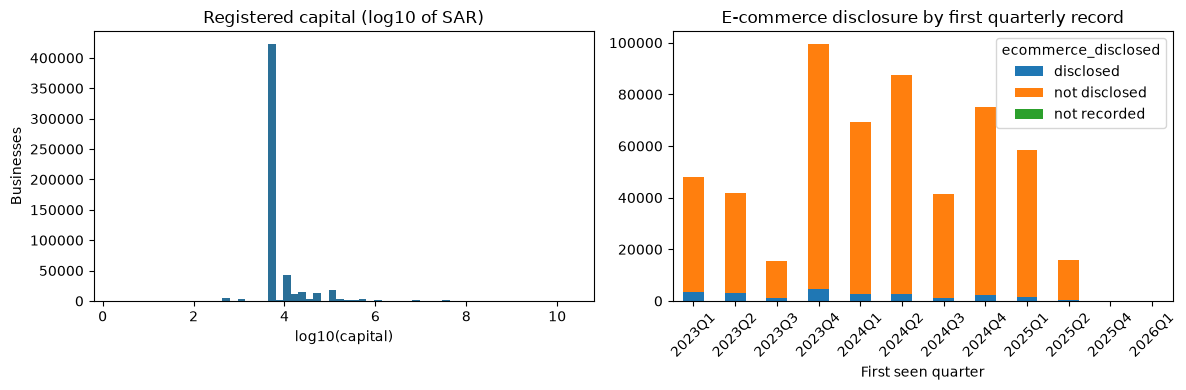

ecommerce_disclosed  disclosed  not disclosed  not recorded
first_seen_quarter                                         
2023Q1                    3372          44530             0
2023Q2                    3024          38951             0
2023Q3                    1014          14571             0
2023Q4                    4736          94694             0
2024Q1                    2535          66676             0
2024Q2                    2620          84872             0
2024Q3                    1319          40070             0
2024Q4                    2256          72775             0
2025Q1                    1725          56643             0
2025Q2                     424          15324             0
2025Q4                       0              0             1
2026Q1                       0              0             4


In [6]:
for column, names in [('legal_form', LEGAL_FORM_NAMES), ('region', REGION_NAMES), ('sector', SECTION_NAMES)]:
    shares = training[column].astype('string').map(lambda v: names.get(v, v)).value_counts(normalize=True, dropna=False)
    print(f'\n{column} (share of training businesses)')
    print(shares.map('{:.1%}'.format).to_string())

capital = training['registered_capital_sar']
print('\nRegistered capital (SAR):')
print(capital.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).map('{:,.0f}'.format).to_string())
print(f'Exactly 5,000 SAR: {(capital == 5000).mean():.1%} | missing: {capital.isna().mean():.2%}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(capital.dropna()), bins=60, color='#2a6f97')
axes[0].set_title('Registered capital (log10 of SAR)'); axes[0].set_xlabel('log10(capital)'); axes[0].set_ylabel('Businesses')
ecommerce = training['ecommerce_disclosed'].map({1: 'disclosed', 0: 'not disclosed'}).astype('string').fillna('not recorded')
pd.crosstab(training['first_seen_quarter'], ecommerce).plot.bar(stacked=True, ax=axes[1], rot=45)
axes[1].set_title('E-commerce disclosure by first quarterly record'); axes[1].set_xlabel('First seen quarter')
plt.tight_layout(); plt.show()
print(pd.crosstab(training['first_seen_quarter'], ecommerce).to_string())

**Result.** Sole proprietorships make up 70.4% of the training businesses and limited liability companies 29.2%; the other
legal forms together hold less than 0.5%. Riyadh holds 38.4% of the businesses, Makkah 19.0% and the Eastern
Province 15.5%. The sector is `unclassified` for 27.5%; construction holds 28.5% and wholesale and retail trade
12.3%. Registered capital has a median of 5,000 SAR; 76.3% of the businesses register exactly 5,000 SAR, the 90th
percentile is 25,000 SAR and the maximum exceeds 20 billion SAR; no training business lacks a capital. The
e-commerce disclosure is recorded for every training business except five first seen from 2025 Q4.

**Interpretation.** Registered capital is, for three businesses in four, the same amount, so it distinguishes few businesses and
describes the registration more than the founder's planned investment. Because the businesses first seen long after
their founding were mostly former branches, almost every training business now has its e-commerce disclosure.

## 7. Stage 5 — Failure Rate by Business Characteristic

Each chart gives the failure rate of each category among the training businesses, with the number of businesses
in brackets; the dashed line is the failure rate of all training businesses. Categories with fewer than 200
businesses are not shown. Capital is divided into groups by its quintiles; because many businesses register
exactly the same capital, groups with the same boundaries are merged.

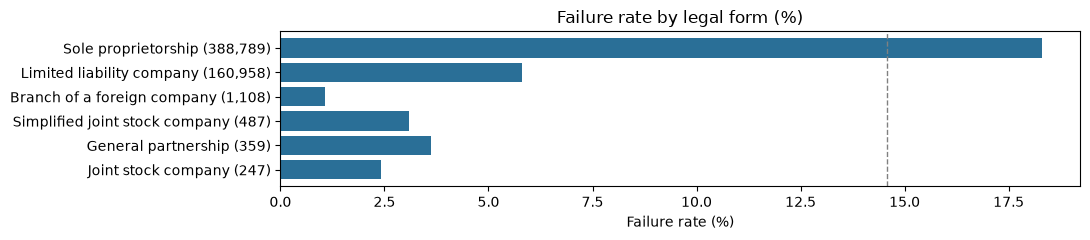

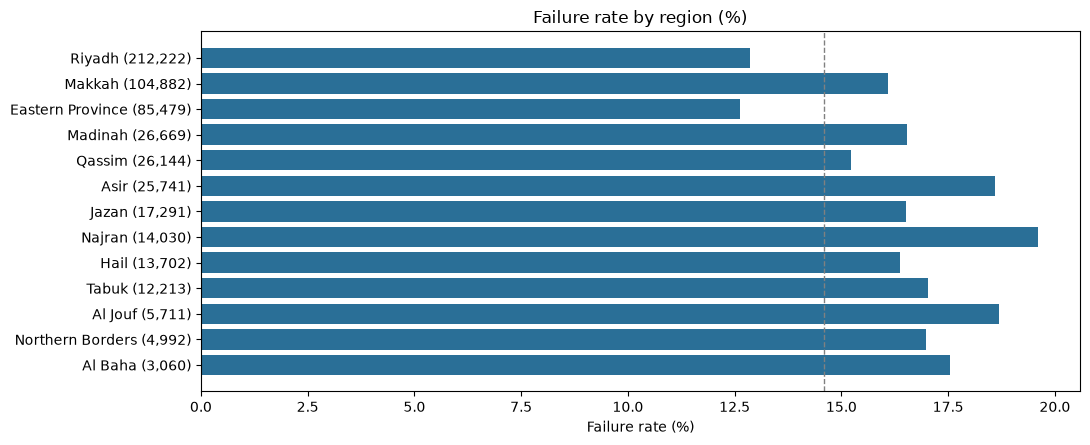

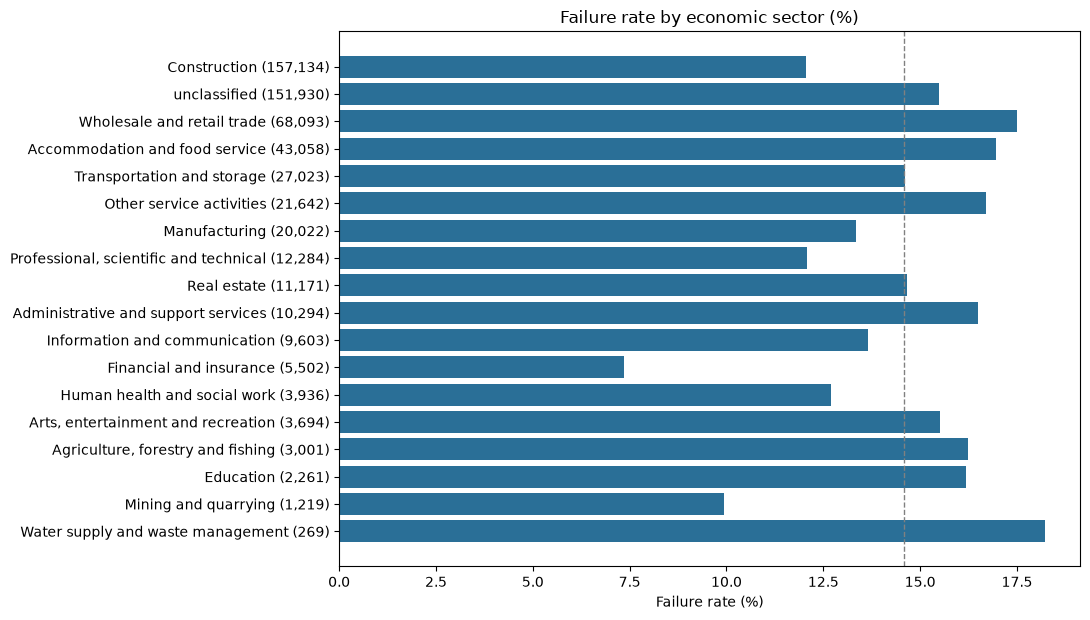

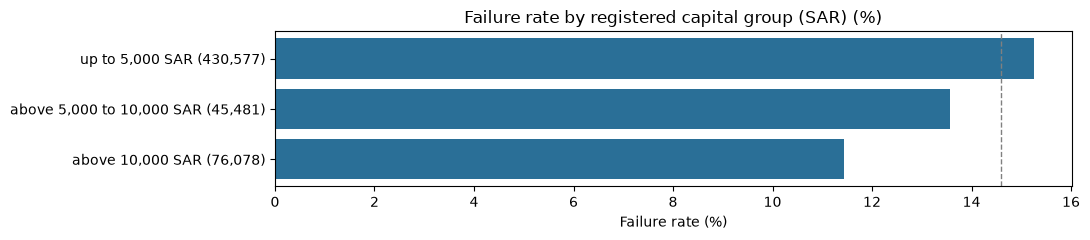

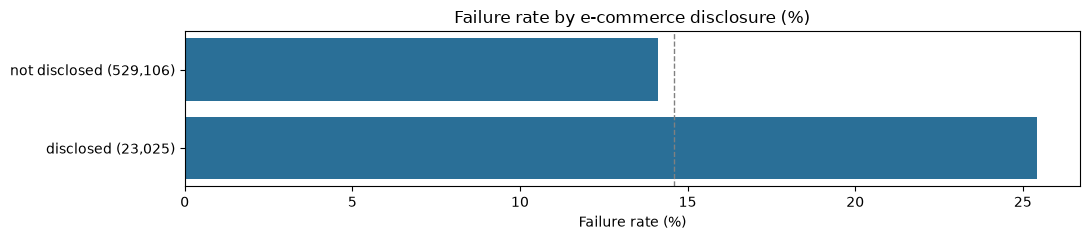

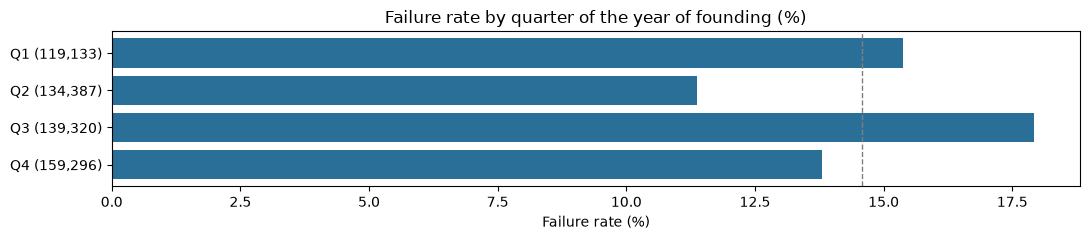


legal form
                               failure rate businesses
value                                                 
Sole proprietorship                   18.3%    388,789
Limited liability company              5.8%    160,958
Branch of a foreign company            1.1%      1,108
Simplified joint stock company         3.1%        487
General partnership                    3.6%        359
Joint stock company                    2.4%        247

region
                 failure rate businesses
value                                   
Riyadh                  12.9%    212,222
Makkah                  16.1%    104,882
Eastern Province        12.6%     85,479
Madinah                 16.5%     26,669
Qassim                  15.2%     26,144
Asir                    18.6%     25,741
Jazan                   16.5%     17,291
Najran                  19.6%     14,030
Hail                    16.4%     13,702
Tabuk                   17.0%     12,213
Al Jouf                 18.7%      5,711
Norther

In [7]:
OVERALL = training['failed'].mean()
def failure_chart(values, title, order=None, min_size=200, file=None):
    table = pd.DataFrame({'value': values, 'failed': training['failed']}).groupby('value', observed=True)['failed'].agg(['mean', 'size'])
    table = table[table['size'] >= min_size]
    table = table.reindex([o for o in order if o in table.index]) if order is not None else table.sort_values('size', ascending=False)
    labels = [f'{v} ({n:,})' for v, n in zip(table.index, table['size'])]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.35 * len(table))))
    ax.barh(labels, table['mean'] * 100, color='#2a6f97')
    ax.axvline(OVERALL * 100, color='grey', ls='--', lw=1)
    ax.invert_yaxis(); ax.set_xlabel('Failure rate (%)'); ax.set_title(title)
    plt.tight_layout()
    if file:
        plt.savefig(FIGURES / f'04_stage5_failure_by_{file}.png', dpi=300)
    plt.show()
    return table.rename(columns={'mean': 'failure rate', 'size': 'businesses'})

tables = {}
tables['legal form'] = failure_chart(training['legal_form'].astype('string').map(LEGAL_FORM_NAMES), 'Failure rate by legal form (%)', file='legal_form')
tables['region'] = failure_chart(training['region'].astype('string').map(REGION_NAMES), 'Failure rate by region (%)', file='region')
tables['sector'] = failure_chart(training['sector'].astype('string').map(SECTION_NAMES), 'Failure rate by economic sector (%)', file='sector')
capital_group = pd.qcut(capital, 5, duplicates='drop')
def capital_label(group):   # readable names for the quintile groups, e.g. "above 5,000 to 10,000 SAR"
    low, high = group.left, group.right
    if group == capital_group.cat.categories[0]:
        return f'up to {high:,.0f} SAR'
    if group == capital_group.cat.categories[-1]:
        return f'above {low:,.0f} SAR'
    return f'above {low:,.0f} to {high:,.0f} SAR'
capital_names = capital_group.map(capital_label).astype('string')
tables['capital'] = failure_chart(capital_names, 'Failure rate by registered capital group (SAR) (%)',
                                  order=[capital_label(c) for c in capital_group.cat.categories], file='capital')
tables['e-commerce'] = failure_chart(ecommerce, 'Failure rate by e-commerce disclosure (%)')
tables['quarter of the year'] = failure_chart('Q' + training['founding_quarter'].str[-1], 'Failure rate by quarter of the year of founding (%)',
                                              order=['Q1', 'Q2', 'Q3', 'Q4'])
for name, table in tables.items():
    print(f'\n{name}'); print(table.to_string(formatters={'failure rate': '{:.1%}'.format, 'businesses': '{:,}'.format}))

**Result.** Sole proprietorships fail at 18.3% and limited liability companies at 5.8%; the other legal forms fail at 1.1% to
3.6%. By region, the failure rate ranges from 12.6% (Eastern Province) and 12.9% (Riyadh) to 19.6% (Najran). By
sector, it ranges from 7.3% (financial and insurance) and 12.1% (construction) to 17.5% (wholesale and retail
trade); unclassified businesses fail at 15.5%. Registered capital forms three groups: up to 5,000 SAR (15.3%), above
5,000 and up to 10,000 SAR (13.6%) and above 10,000 SAR (11.4%). Businesses that disclosed e-commerce fail at 25.4%,
those that did not at 14.1%. By quarter of the year, the failure rate ranges from 11.4% (Q2) to 17.9% (Q3).

**Interpretation.** Legal form shows the largest and clearest difference among the business characteristics; region, sector, capital
and e-commerce show moderate differences. The e-commerce disclosure is now a characteristic of the business rather
than of the period in which it was recorded. The quarter of the year mixes seasonality with the differences between
founding quarters: Q2 contains 2024 Q2 (8.7%) and Q3 contains 2023 Q3 (23.9%).

## 8. Stage 6 — Missing Values by Outcome

If a characteristic were missing much more often for one outcome, its absence would itself reveal the outcome.
The table gives, for each characteristic, the share of missing values among the surviving and the failed training
businesses; for the sector, `unclassified` is counted as missing. A difference above 5 points is marked in the last column.

                   missing (survived) missing (failed) difference (points) above 5 points
region                           0.0%             0.0%                +0.0               
city                             0.0%             0.0%                +0.0               
legal_form                       0.0%             0.0%                +0.0               
registered capital               0.0%             0.0%                +0.0               
e-commerce                       0.0%             0.0%                +0.0               
sector                          27.2%            29.2%                +2.0               
founding date                    0.0%             0.0%                +0.0               


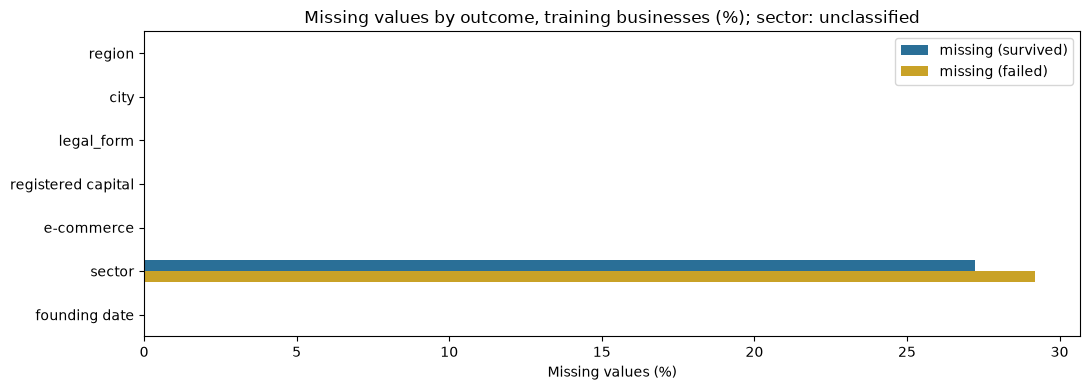

In [8]:
missing = pd.DataFrame({
    'region': training['region'].isna(), 'city': training['city'].isna(), 'legal_form': training['legal_form'].isna(),
    'registered capital': training['registered_capital_sar'].isna(), 'e-commerce': training['ecommerce_disclosed'].isna(),
    'sector': training['sector'] == 'unclassified', 'founding date': training['founding_date'].isna()})
by_outcome = pd.DataFrame({'missing (survived)': missing[training['failed'] == 0].mean(),
                           'missing (failed)': missing[training['failed'] == 1].mean()})
by_outcome['difference (points)'] = (by_outcome['missing (failed)'] - by_outcome['missing (survived)']) * 100
by_outcome['above 5 points'] = np.where(by_outcome['difference (points)'].abs() > 5, 'yes', '')
print(by_outcome.to_string(formatters={'missing (survived)': '{:.1%}'.format, 'missing (failed)': '{:.1%}'.format,
                                       'difference (points)': '{:+.1f}'.format}))
ax = (by_outcome[['missing (survived)', 'missing (failed)']] * 100).plot.barh(color=['#2a6f97', '#c9a227'], figsize=(11, 4))
ax.invert_yaxis(); ax.set_xlabel('Missing values (%)'); ax.set_title('Missing values by outcome, training businesses (%); sector: unclassified')
plt.tight_layout(); plt.savefig(FIGURES / '04_stage6_missing_by_outcome.png', dpi=300); plt.show()

**Result.** Region, city, legal form, founding date, registered capital and e-commerce are never missing for the training
businesses of either outcome. The sector is `unclassified` for 29.2% of the failed businesses against 27.2% of the
surviving ones (+2.0 points). No difference exceeds 5 points.

**Interpretation.** No characteristic is missing in a way that reveals the outcome. Before preprocessing resolved the former branches,
the e-commerce value was missing for 13.2% of the failed businesses against 0.4% of the surviving ones; that
difference has disappeared. The difference for the sector is small and comes from the business name, which is known
at the founding.

## 9. Stage 7 — Failure Rate by Founding Month

The number of businesses founded each month and their failure rate show whether the founding quarters differ in
composition, for example through the wave of limited liability companies of 2024 Q2 (Notebook 02, section 6.2.2).

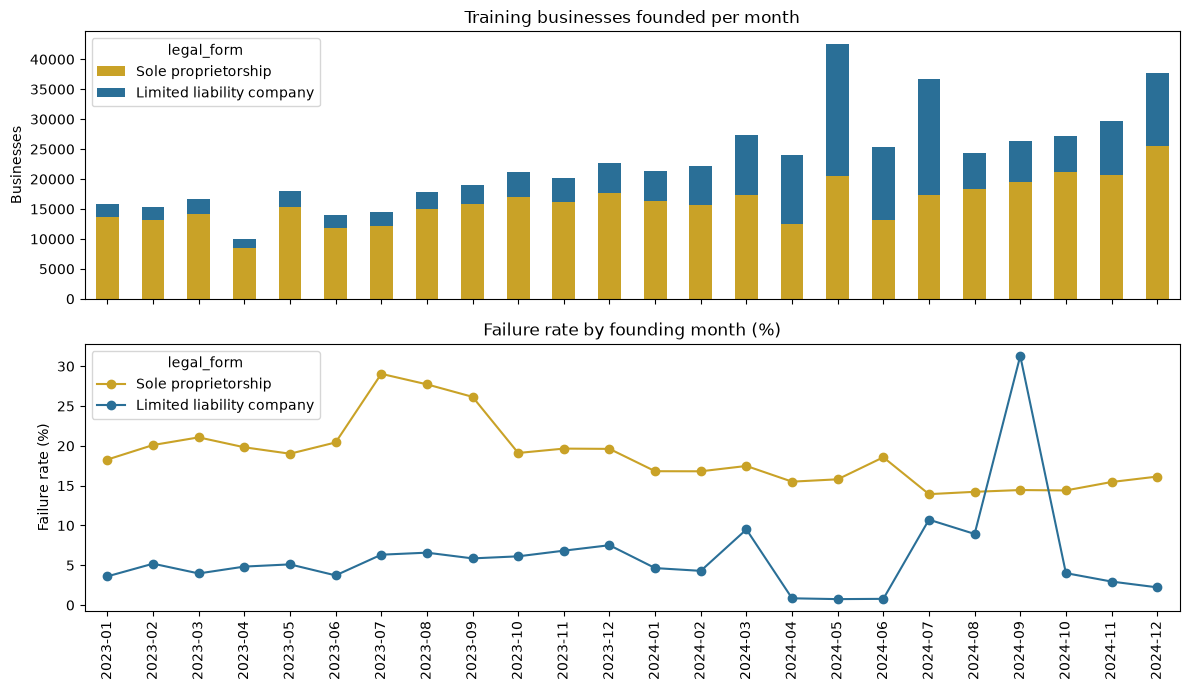

                       businesses                                  failure rate                          
legal_form    Sole proprietorship Limited liability company Sole proprietorship Limited liability company
founding_date                                                                                            
2023-01                    13,745                     2,078               0.183                     0.036
2023-02                    13,126                     2,134               0.201                     0.052
2023-03                    14,221                     2,415               0.211                     0.040
2023-04                     8,471                     1,530               0.198                     0.048
2023-05                    15,279                     2,660               0.190                     0.051
2023-06                    11,811                     2,118               0.204                     0.037
2023-07                    12,139             

In [9]:
month = training['founding_date'].dt.to_period('M').astype(str)
monthly = training.groupby([month, training['legal_form'].astype('string').map(LEGAL_FORM_NAMES)])['failed'].agg(['size', 'mean']).unstack()
main_forms = ['Sole proprietorship', 'Limited liability company']
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly['size'][main_forms].plot.bar(stacked=True, ax=axes[0], color=['#c9a227', '#2a6f97'])
axes[0].set_title('Training businesses founded per month'); axes[0].set_ylabel('Businesses')
(monthly['mean'][main_forms] * 100).plot(ax=axes[1], marker='o', color=['#c9a227', '#2a6f97'], use_index=False)
axes[1].set_title('Failure rate by founding month (%)'); axes[1].set_ylabel('Failure rate (%)')
axes[1].set_xticks(range(len(monthly))); axes[1].set_xticklabels(monthly.index, rotation=90)
plt.tight_layout(); plt.show()
print(pd.concat({'businesses': monthly['size'][main_forms], 'failure rate': monthly['mean'][main_forms]}, axis=1)
      .to_string(float_format=lambda v: f'{v:.3f}' if v < 1 else f'{v:,.0f}'))

**Result.** Limited liability companies founded from April to June 2024 fail at 0.8% to 0.9%, against 2.2% to 10.7% for those
founded in the other months from January 2023 to December 2024; those founded in September 2024 fail at 31.3%. The
number of limited liability companies founded per month reaches 21,998 in May 2024, against 2,078 to 19,385 in the
other months. The failure rate of sole proprietorships is highest for those founded from July to September 2023
(26.2% to 29.0%) and lies between 13.9% and 21.1% in the other months.

**Interpretation.** The failure rate of limited liability companies changes sharply with the founding month: the companies founded from
April to June 2024, the wave of section 6.2.2 of Notebook 02, almost all survive, while those founded in September
2024 fail several times more often than usual. These companies are checked in the records of 2025 Q2 and 2025 Q3
respectively, the latter being incomplete. The records do not show whether these differences come from the
businesses or from the records used for the check; the founding quarter is therefore a likely source of differences
that a model may confuse with the effect of the legal form.

## 10. Limitations

1. Only the training businesses are studied; the relations may differ for the validation and test businesses.
2. Every relation shown is that of one characteristic alone; the characteristics are related to one another.
3. The English names of the sectors, legal forms and regions in the charts are translations by the team; the official names are in Arabic.
4. The failure rate by founding month mixes the businesses themselves with the completeness of the records used for their survival check.
5. The former branches have no label, so the outcome of businesses created from an existing branch is not described.

## 11. Summary of Findings

1. Every problem found in the raw records (Notebook 01) is resolved in the dataset or stated with the businesses it concerns (Stage 1); no business lacks a registration number, a founding date or a real capital.
2. The training set holds 552,136 businesses founded from 2023 Q1 to 2024 Q4, with a failure rate of 14.6% (from 8.7% to 23.9% by founding quarter). The validation and test businesses were not examined.
3. Identifying the former branches reduced the training businesses first recorded after their survival check from 20,769 to 2,110, and those that failed and reappeared later from 26,362 to 7,602.
4. Businesses checked in an incomplete record fail at 16.6%, against 14.6% for all training businesses.
5. Legal form shows the largest difference in failure: 18.3% for sole proprietorships against 5.8% for limited liability companies.
6. Three businesses in four register exactly 5,000 SAR, so registered capital distinguishes few businesses.
7. No characteristic is missing in a way that reveals the outcome; the e-commerce difference found before (13.2% of failed against 0.4% of surviving businesses) has disappeared.
8. Limited liability companies founded from April to June 2024 almost all survive (failure 0.8% to 0.9%), while those founded in September 2024 fail at 31.3%; the cause is not established.